# Prompt-copy overlap + BERTopic (5 topics)

Two parts, kept separate on purpose:

1. **Prompt-copy analysis** — how much of each reasoning trace resembles the extraction instructions,
   per run and per report.
2. **BERTopic with 5 topics** on the remaining (non-copy) sentences, plus a **2D UMAP** scatter plot.

Same five runs as `trace_topics_base.ipynb` (gpt-oss low/medium/high, DeepSeek high/max).
Embeddings are local (`all-MiniLM-L6-v2`); no API calls.

## 0. Setup

In [19]:
import hashlib
import json
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_colwidth", 140)
pd.set_option("display.width", 200)

ROOT = Path.cwd().resolve()
if not (ROOT / "output").is_dir():
    ROOT = ROOT.parent

OUT = ROOT / "output"
DERIVED = ROOT / "analysis" / "derived" / "topics_prompt_bertopic"
DERIVED.mkdir(parents=True, exist_ok=True)

SEED = 42
N_TOPICS = 5  # same coarse setting as trace_topics_base
EMBED_MODEL = "all-MiniLM-L6-v2"
PROMPT_COPY_THRESHOLD = 0.85
DS = "DeepSeek-V4-Flash-0731"

RUN_DIRS = {
    "gpt-oss low": OUT / "gpt-oss-120b_low" / "1ebb0c8dc26d4681bda9555908104e67",
    "gpt-oss medium": OUT / "gpt-oss-120b_medium" / "8b438992f14c4b6da28ec581572dcc85",
    "gpt-oss high": OUT / "gpt-oss-120b_high" / "10d7970dd8304f8cb06d174a851f8e2a",
    "DeepSeek high": OUT / f"{DS}_high" / "2c50bb4fcde3462f9d6cbe6516b686c9",
    "DeepSeek max": OUT / f"{DS}_max" / "4c3229ed86dc4fe6b1ef4b95c64ca68d",
}
KEEP_RUNS = list(RUN_DIRS)
SPLIT = re.compile(r"\n+|(?<=[.!?])\s+(?=[A-Z\"'(\[])")


def sentences(text: str) -> list[str]:
    out = []
    for part in SPLIT.split(text or ""):
        part = re.sub(r"\s+", " ", part).strip(" -*•\t")
        if len(part.split()) >= 3:
            out.append(part)
    return out

## 1. Load traces and split into sentences

In [20]:
rows = []
for run, run_dir in RUN_DIRS.items():
    for path in sorted((run_dir / "reasoning_traces").glob("*.jsonl")):
        with path.open(encoding="utf-8") as f:
            for i, line in enumerate(f):
                c = json.loads(line)
                reasoning = c.get("reasoning_content")
                if not reasoning or not str(reasoning).strip():
                    continue
                rows.append({
                    "run": run,
                    "report": Path(str(c["pdf"]).replace("\\", "/")).name,
                    "call_index": i,
                    "prompt": c.get("prompt"),
                    "reasoning": reasoning,
                })

pages = pd.DataFrame(rows)
pages["run"] = pd.Categorical(pages["run"], KEEP_RUNS, ordered=True)
pages["trace_id"] = np.arange(len(pages))

seg = pd.DataFrame(
    [
        (row.trace_id, row.run, row.report, i, text)
        for row in pages.itertuples()
        for i, text in enumerate(sentences(row.reasoning))
    ],
    columns=["trace_id", "run", "report", "pos", "text"],
)
seg["run"] = pd.Categorical(seg["run"], KEEP_RUNS, ordered=True)

print(f"{len(pages):,} traces  |  {len(seg):,} sentences  |  {seg.text.nunique():,} unique")
display(pages.groupby("run", observed=True).size().rename("traces").to_frame())

4,858 traces  |  226,557 sentences  |  130,169 unique


,traces
run,
gpt-oss low,973
gpt-oss medium,973
gpt-oss high,973
DeepSeek high,972
DeepSeek max,967


## 2. Embeddings + prompt-copy scores

Each unique sentence is embedded once. Prompt-copy = max cosine similarity to any
**instruction** sentence (prompt text before `Here is the excerpt`) above 0.85.

We keep both the binary flag and the continuous similarity for later plots.

In [21]:
from sentence_transformers import SentenceTransformer

embedder = SentenceTransformer(EMBED_MODEL)
uniq = seg.text.drop_duplicates().tolist()
key = hashlib.sha1("\n".join(uniq).encode()).hexdigest()[:12]
emb_path = DERIVED / f"embeddings_{key}.npy"

if emb_path.exists():
    E = np.load(emb_path)
    print(f"loaded cached embeddings: {E.shape}")
else:
    E = embedder.encode(uniq, batch_size=256, normalize_embeddings=True, show_progress_bar=True)
    np.save(emb_path, E)
    print(f"saved embeddings: {E.shape} → {emb_path.name}")

sample_prompt = next(
    (p for p in pages["prompt"] if isinstance(p, str) and "Here is the excerpt" in p),
    None,
)
if sample_prompt is None:
    raise RuntimeError("No stored prompt with 'Here is the excerpt' found in traces.")

instructions = sentences(sample_prompt.split("Here is the excerpt")[0])
I = embedder.encode(instructions, normalize_embeddings=True)

sent = pd.DataFrame({
    "text": uniq,
    "prompt_sim": (E @ I.T).max(axis=1),
    "closest_instruction": (E @ I.T).argmax(axis=1),
})
sent["prompt_copy"] = sent.prompt_sim > PROMPT_COPY_THRESHOLD
sent["instruction_text"] = sent.closest_instruction.map(lambda i: instructions[int(i)])

seg = seg.merge(sent[["text", "prompt_sim", "prompt_copy", "instruction_text"]], on="text", how="left")

print(f"{len(instructions)} instruction sentences")
print(f"prompt copies: {seg.prompt_copy.mean():.1%} of sentence occurrences")
display(seg.groupby("run", observed=True)["prompt_copy"].mean().rename("share prompt copies").to_frame())

Loading weights: 100%|██████████| 103/103 [00:00<00:00, 6172.77it/s]


loaded cached embeddings: (130169, 384)
21 instruction sentences
prompt copies: 3.8% of sentence occurrences


,share prompt copies
run,
gpt-oss low,0.002951
gpt-oss medium,0.014271
gpt-oss high,0.052606
DeepSeek high,0.024385
DeepSeek max,0.031774


## 3. Prompt-copy share per run and per report

Per-trace share = fraction of sentences in that call labelled as prompt copy.
We also report mean continuous `prompt_sim`.

,n_traces,prompt_copy_share_mean,prompt_copy_share_median,prompt_sim_mean
run,,,,
gpt-oss low,973,0.001604,0.00,0.424159
gpt-oss medium,973,0.008281,0.00,0.462193
gpt-oss high,973,0.082213,0.05,0.458670
DeepSeek high,972,0.010602,0.00,0.427076
DeepSeek max,967,0.013074,0.00,0.426649


/var/folders/5g/hwl59ykx7pb0dd5drwxxmk3w0000gn/T/ipykernel_19722/1723478647.py:38: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[0].boxplot(data, tick_labels=order, vert=True, showfliers=False)
/var/folders/5g/hwl59ykx7pb0dd5drwxxmk3w0000gn/T/ipykernel_19722/1723478647.py:44: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  axes[1].boxplot(data2, tick_labels=order, vert=True, showfliers=False)


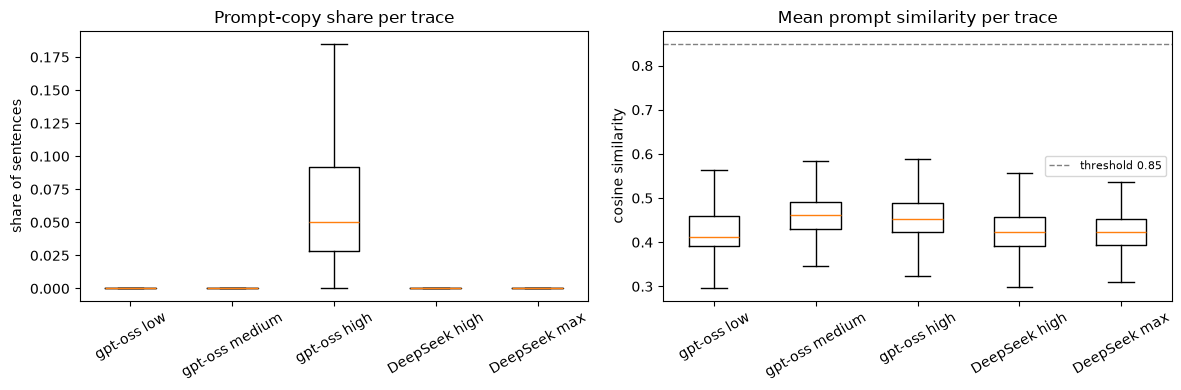

Highest prompt-copy share reports (mean over traces in that run):


,run,report,n_traces,prompt_copy_share,prompt_sim_mean
279,gpt-oss high,Daimler_2020_report.pdf,7,0.193036,0.531469
391,gpt-oss high,salzgitter ag_2018_report.pdf,7,0.176869,0.504627
317,gpt-oss high,dampskibsselskabet norden_2019_report.pdf,7,0.173062,0.528717
686,DeepSeek max,uniper_2019_report.pdf,7,0.068588,0.487062
682,DeepSeek max,toshiba tec corp_2022_report.pdf,7,0.056537,0.490347
561,DeepSeek max,aixtron_2020_report.pdf,7,0.051154,0.471700
428,DeepSeek high,apollo commercial real estate fina_2019_report.pdf,7,0.048154,0.462660
1,gpt-oss low,Daimler_2020_report.pdf,7,0.047619,0.454534
543,DeepSeek high,toshiba tec corp_2022_report.pdf,7,0.047150,0.476917
180,gpt-oss medium,dic corp_2017_report.pdf,7,0.046569,0.489504


In [22]:
per_trace = (
    seg.groupby(["run", "report", "trace_id"], observed=True)
    .agg(
        n_sentences=("text", "size"),
        prompt_copy_share=("prompt_copy", "mean"),
        prompt_sim_mean=("prompt_sim", "mean"),
        prompt_sim_median=("prompt_sim", "median"),
    )
    .reset_index()
)

per_report = (
    per_trace.groupby(["run", "report"], observed=True)
    .agg(
        n_traces=("trace_id", "size"),
        n_sentences=("n_sentences", "sum"),
        prompt_copy_share=("prompt_copy_share", "mean"),
        prompt_sim_mean=("prompt_sim_mean", "mean"),
    )
    .reset_index()
)

run_summary = (
    per_trace.groupby("run", observed=True)
    .agg(
        n_traces=("trace_id", "size"),
        prompt_copy_share_mean=("prompt_copy_share", "mean"),
        prompt_copy_share_median=("prompt_copy_share", "median"),
        prompt_sim_mean=("prompt_sim_mean", "mean"),
    )
)
display(run_summary)

fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=False)

order = KEEP_RUNS
data = [per_trace.loc[per_trace.run == r, "prompt_copy_share"] for r in order]
axes[0].boxplot(data, tick_labels=order, vert=True, showfliers=False)
axes[0].set_title("Prompt-copy share per trace")
axes[0].set_ylabel("share of sentences")
axes[0].tick_params(axis="x", rotation=30)

data2 = [per_trace.loc[per_trace.run == r, "prompt_sim_mean"] for r in order]
axes[1].boxplot(data2, tick_labels=order, vert=True, showfliers=False)
axes[1].set_title("Mean prompt similarity per trace")
axes[1].set_ylabel("cosine similarity")
axes[1].axhline(PROMPT_COPY_THRESHOLD, color="gray", ls="--", lw=1, label=f"threshold {PROMPT_COPY_THRESHOLD}")
axes[1].legend(fontsize=8)
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

print("Highest prompt-copy share reports (mean over traces in that run):")
display(
    per_report.sort_values("prompt_copy_share", ascending=False)
    .groupby("run", observed=True).head(3)
    [["run", "report", "n_traces", "prompt_copy_share", "prompt_sim_mean"]]
)

### Which instruction sentences are copied most often?

In [23]:
copied = seg.loc[seg.prompt_copy]
if len(copied):
    top_instr = (
        copied.groupby("instruction_text", observed=True)
        .size()
        .sort_values(ascending=False)
        .head(12)
        .rename("n_copy_occurrences")
        .to_frame()
    )
    display(top_instr)

    by_run = (
        copied.groupby(["run", "instruction_text"], observed=True)
        .size()
        .rename("n")
        .reset_index()
    )
    # top 5 instructions overall, counts per run
    top5 = top_instr.head(5).index.tolist()
    pivot = (
        by_run[by_run.instruction_text.isin(top5)]
        .pivot_table(index="instruction_text", columns="run", values="n", fill_value=0)
        .reindex(columns=KEEP_RUNS)
    )
    display(pivot)
else:
    print("No prompt-copy sentences at this threshold.")

,n_copy_occurrences
instruction_text,
"Do not extract all subcategories of Scope 3, but only total values if total values are available for Scope 3.",965
"Only extract absolute values representing total CO2 emissions (e.g., in tons).",853
You are a climate analyst tasked with extracting specific absolute numerical data from corporate reports.,809
"Only extract value referring to Scope 1, Scope 2 or Scope 3 separately.",799
"If the subtype ""market-based"" or ""location-based"" is not mentioned for a value of Scope 2, always assume that the value refers to the KPI Scope 2 (location-based).",678
Do not extract values representing a sum of any the scopes.,607
Only extract values which refer to the whole company.,583
Footnotes or annotations in metric names should be treated as references and ignored for the extraction process.,349
"Do not extract any relative values such as percentages, year-over-year changes, or trends.",298


run,gpt-oss low,gpt-oss medium,gpt-oss high,DeepSeek high,DeepSeek max
instruction_text,,,,,
"Do not extract all subcategories of Scope 3, but only total values if total values are available for Scope 3.",0.0,32.0,337.0,204.0,392.0
"If the subtype ""market-based"" or ""location-based"" is not mentioned for a value of Scope 2, always assume that the value refers to the KPI Scope 2 (location-based).",0.0,7.0,342.0,120.0,209.0
"Only extract absolute values representing total CO2 emissions (e.g., in tons).",1.0,35.0,542.0,105.0,170.0
"Only extract value referring to Scope 1, Scope 2 or Scope 3 separately.",6.0,38.0,364.0,160.0,231.0
You are a climate analyst tasked with extracting specific absolute numerical data from corporate reports.,0.0,0.0,797.0,2.0,10.0


## 4. BERTopic with 5 topics (non-copy sentences only)

Prompt copies are excluded so they do not dominate clusters.
UMAP → k-means with fixed `N_TOPICS=5`.

In [24]:
from bertopic import BERTopic
from bertopic.representation import KeyBERTInspired
from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import CountVectorizer
from umap import UMAP

keep_mask = ~sent.prompt_copy.to_numpy()
docs = sent.loc[keep_mask, "text"].tolist()
E_fit = E[keep_mask]

umap_model = UMAP(
    n_neighbors=15,
    n_components=5,
    min_dist=0.0,
    metric="cosine",
    random_state=SEED,
)

topic_model = BERTopic(
    embedding_model=embedder,
    umap_model=umap_model,
    hdbscan_model=KMeans(n_clusters=N_TOPICS, random_state=SEED, n_init=10),
    vectorizer_model=CountVectorizer(
        stop_words="english",
        ngram_range=(1, 2),
        min_df=5,
        token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z\-]+\b",
    ),
    representation_model=KeyBERTInspired(),
    calculate_probabilities=False,
)

topics, _ = topic_model.fit_transform(docs, E_fit)
sent_fit = sent.loc[keep_mask].copy()
sent_fit["topic"] = topics

info = topic_model.get_topic_info()
topic_info = pd.DataFrame({
    "topic": info.Topic,
    "n": info.Count,
    "keywords": info.Representation.map(lambda w: ", ".join(w[:8])),
})
display(topic_info)

seg = seg.merge(sent_fit[["text", "topic"]], on="text", how="left")
print(f"{N_TOPICS} topics on {keep_mask.sum():,} unique non-copy sentences")
print(f"labelled occurrences: {seg.topic.notna().sum():,} / {len(seg):,}")

,topic,n,keywords
0,0,45473,"scope total, total scope, total values, scope scope, scopes, values total, scope, values"
1,1,30335,"numbers, range, number, total company, annual, fiscal year, values, refer company"
2,2,27014,"values excerpt, extract values, values need, values, excerpt includes, need extract, extract, null"
3,3,15836,"entries, extract total, excerpt does, extract values, values need, total values, says extract, values"
4,4,8620,"scope scope, scope, scope market-based, scope location-based, location-based scope, range, values, unit year"


5 topics on 127,278 unique non-copy sentences
labelled occurrences: 217,982 / 226,557


### Example sentences per topic

In [25]:
for t in sorted(sent_fit.topic.unique()):
    kw = topic_info.loc[topic_info.topic == t, "keywords"].iloc[0]
    examples = sent_fit.loc[sent_fit.topic == t, "text"].head(4).tolist()
    print(f"\n### Topic {t}  ({topic_info.loc[topic_info.topic == t, 'n'].iloc[0]} unique)  |  {kw}")
    for ex in examples:
        print(f"  - {ex[:180]}")


### Topic 0  (45473 unique)  |  scope total, total scope, total values, scope scope, scopes, values total, scope, values
  - In excerpt only business travel GHG emissions given, not total company.
  - Unit t CO2e.
  - No absolute numbers for total emissions.
  - In excerpt only carbon footprint absolute emissions for portfolio, not company.

### Topic 1  (30335 unique)  |  numbers, range, number, total company, annual, fiscal year, values, refer company
  - We need extract values for 2020-2022 (within 2013-2024).
  - We need extract values: from excerpt we have total company?
  - But that's for Infrastructure Equity sub-portfolio, not whole company.
  - So no whole company values.

### Topic 2  (27014 unique)  |  values excerpt, extract values, values need, values, excerpt includes, need extract, extract, null
  - So output empty list.
  - We need extract values but none present in excerpt.
  - So no entries.
  - Return empty list.

### Topic 3  (15836 unique)  |  entries, extract tot

## 5. UMAP plot (2D)

Separate 2D UMAP on the same non-copy embeddings, coloured by the 10 BERTopic labels.
A second panel colours a random subsample by run.

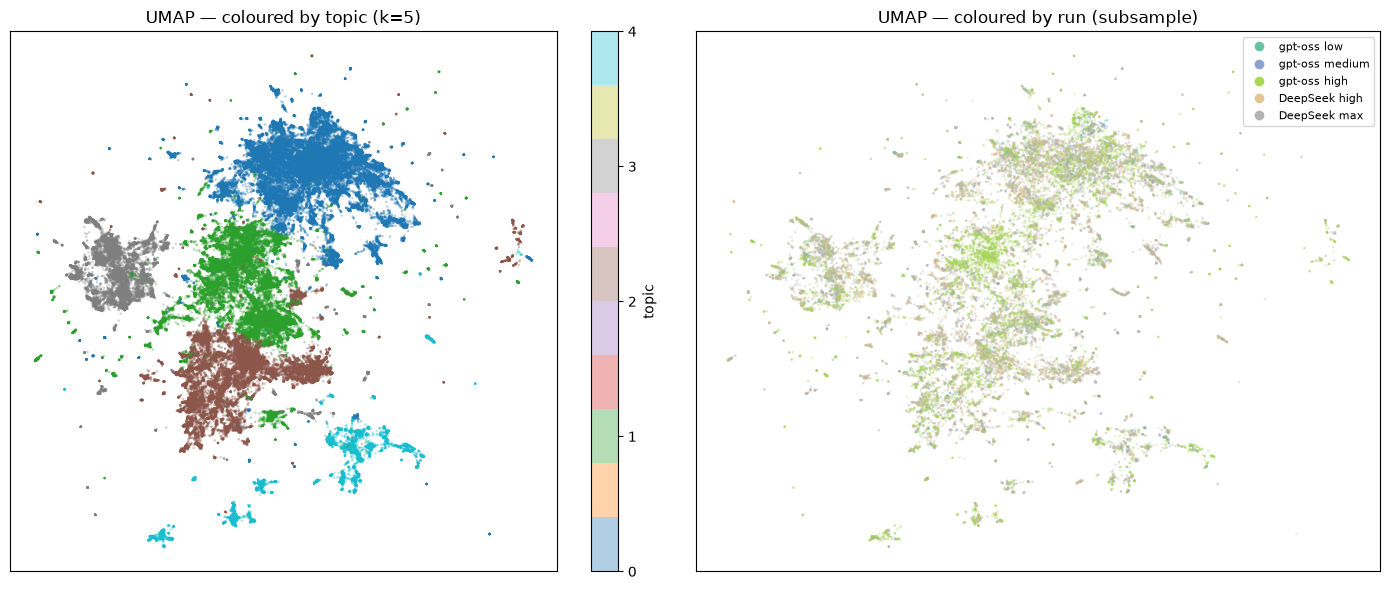

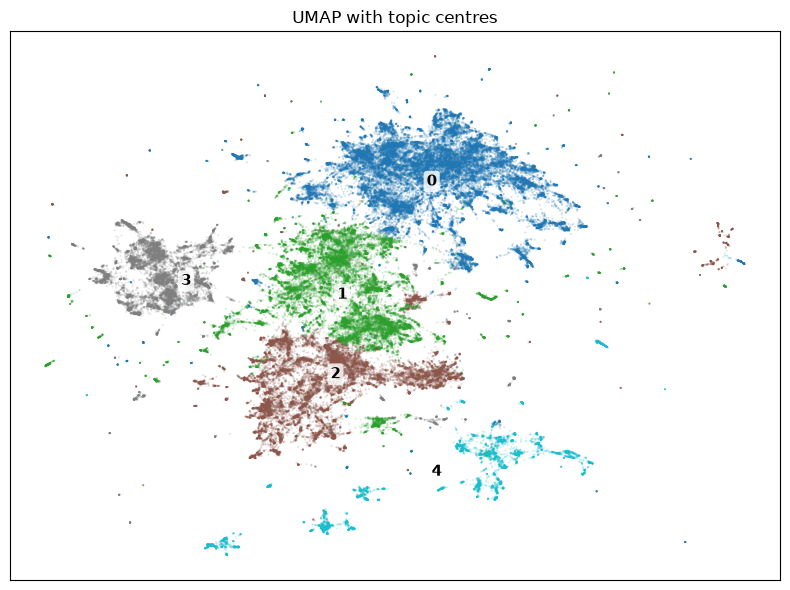

In [26]:
umap_2d = UMAP(
    n_neighbors=15,
    n_components=2,
    min_dist=0.1,
    metric="cosine",
    random_state=SEED,
)
xy = umap_2d.fit_transform(E_fit)
plot_df = sent_fit.copy()
plot_df["x"] = xy[:, 0]
plot_df["y"] = xy[:, 1]

# attach a majority run label for unique sentences (first occurrence)
run_of_text = seg.drop_duplicates("text").set_index("text")["run"]
plot_df["run"] = plot_df["text"].map(run_of_text)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

sc0 = axes[0].scatter(
    plot_df.x, plot_df.y,
    c=plot_df.topic, cmap="tab10", s=3, alpha=0.35, linewidths=0,
)
axes[0].set_title(f"UMAP — coloured by topic (k={N_TOPICS})")
axes[0].set_xticks([]); axes[0].set_yticks([])
cbar = fig.colorbar(sc0, ax=axes[0], ticks=range(N_TOPICS))
cbar.set_label("topic")

# subsample for run colours so the plot stays readable
rng = np.random.default_rng(SEED)
idx = rng.choice(len(plot_df), size=min(25_000, len(plot_df)), replace=False)
sub = plot_df.iloc[idx]
run_codes = pd.Categorical(sub["run"], KEEP_RUNS, ordered=True).codes
sc1 = axes[1].scatter(
    sub.x, sub.y,
    c=run_codes, cmap="Set2", s=3, alpha=0.35, linewidths=0,
)
axes[1].set_title("UMAP — coloured by run (subsample)")
axes[1].set_xticks([]); axes[1].set_yticks([])
handles = [
    plt.Line2D([0], [0], marker="o", color="w",
               markerfacecolor=plt.cm.Set2(i / max(len(KEEP_RUNS) - 1, 1)),
               markersize=8, label=r)
    for i, r in enumerate(KEEP_RUNS)
]
axes[1].legend(handles=handles, fontsize=8, loc="best", frameon=True)

plt.tight_layout()
plt.show()

# topic centres for a quick legend
centres = plot_df.groupby("topic")[["x", "y"]].mean()
fig, ax = plt.subplots(figsize=(8, 6))
ax.scatter(plot_df.x, plot_df.y, c=plot_df.topic, cmap="tab10", s=2, alpha=0.2, linewidths=0)
for t, row in centres.iterrows():
    ax.text(row.x, row.y, str(t), fontsize=11, fontweight="bold",
            ha="center", va="center",
            bbox=dict(boxstyle="round,pad=0.2", fc="white", alpha=0.8, lw=0))
ax.set_title("UMAP with topic centres")
ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

## 6. Topic mix by run

run,gpt-oss low,gpt-oss medium,gpt-oss high,DeepSeek high,DeepSeek max
topic,,,,,
0,26.3%,28.2%,25.7%,30.0%,31.4%
1,8.5%,13.1%,20.4%,18.1%,18.9%
2,49.2%,20.7%,32.6%,26.3%,25.7%
3,13.1%,14.8%,9.5%,12.3%,11.4%
4,2.9%,23.2%,11.9%,13.3%,12.6%


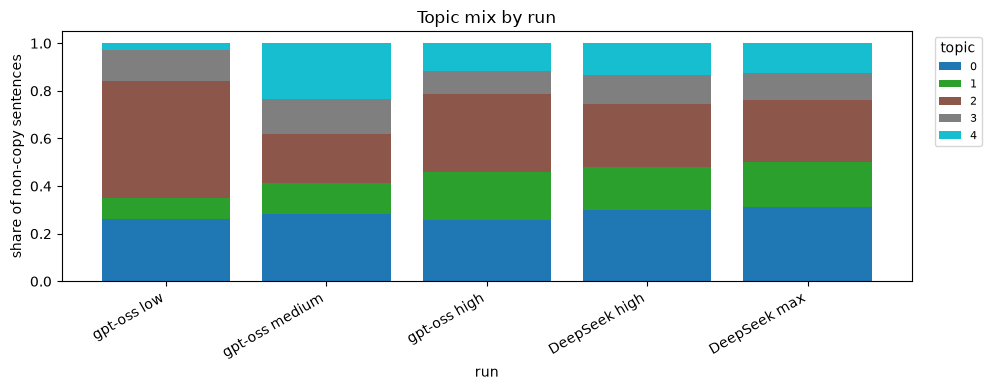

wrote tables under /Users/reginapichler/Documents/Uni/Master/Seminar/gist-reasoning-traces/analysis/derived/topics_prompt_bertopic


In [27]:
labelled = seg.dropna(subset=["topic"]).copy()
labelled["topic"] = labelled["topic"].astype(int)

mix = (
    labelled.groupby(["run", "topic"], observed=True)
    .size()
    .groupby("run", observed=True)
    .transform(lambda s: s / s.sum())
    .rename("share")
    .reset_index()
    .pivot(index="topic", columns="run", values="share")
    .reindex(columns=KEEP_RUNS)
    .fillna(0)
)
display(mix.style.format("{:.1%}"))

ax = mix.T.plot(kind="bar", stacked=True, figsize=(10, 4), colormap="tab10", width=0.8)
ax.set_ylabel("share of non-copy sentences")
ax.set_title("Topic mix by run")
ax.legend(title="topic", bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

per_trace.to_parquet(DERIVED / "per_trace_prompt_overlap.parquet", index=False)
per_report.to_parquet(DERIVED / "per_report_prompt_overlap.parquet", index=False)
topic_info.to_csv(DERIVED / "topic_info_10.csv", index=False)
print(f"wrote tables under {DERIVED}")

## Notes

- Prompt-copy threshold 0.85 is inherited from `trace_topics.ipynb`; tweak if needed.
- UMAP layout is stochastic beyond the seed and is for exploration, not a metric space.
- Topics are clusters of similar wording — not a validated reasoning codebook.